In [ ]:
!pip install pandas numpy matplotlib scikit-learn scipy statsmodels

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

DATA_DIR = "/content/drive/MyDrive/GSE149009"

print(os.listdir(DATA_DIR))

['GSE149009_clean_clinical_metadata.csv', 'GSE149009_gbm_rna_deseq2.txt']


In [ ]:
import pandas as pd

clinical = pd.read_csv(
    "/content/drive/MyDrive/GSE149009/GSE149009_clean_clinical_metadata.csv"
)

print("Clinical data shape:", clinical.shape)
print("\nColumns:")
print(clinical.columns.tolist())

clinical.head()

Clinical data shape: (68, 12)

Columns:
['patient_id', 'gsm_as_listed_in_dictionary', 'disease_state', 'age', 'gender', 'idh_mutation', 'survival_days', 'tissue', 'gsm', 'gsm_mapping_note', 'expr_column', 'survival_missing']


,patient_id,gsm_as_listed_in_dictionary,disease_state,age,gender,idh_mutation,survival_days,tissue,gsm,gsm_mapping_note,expr_column,survival_missing
0,G1,GSM4487293,GBM (IV),53.0,M,WT,22.0,GBM tumor tissue,GSM4487293,GEO Series roster sequence; OtB mapping cross-...,OtB6179,False
1,G2,GSM4487294,GBM (IV),69.0,M,NaN,25.0,GBM tumor tissue,GSM4487294,GEO Series roster sequence; OtB mapping cross-...,OtB6180,False
2,G3,GSM4487295,GBM (IV),36.0,M,WT,31.0,GBM tumor tissue,GSM4487295,GEO Series roster sequence; OtB mapping cross-...,OtB6181,False
3,G4,GSM4487296,GBM (IV),68.0,M,NaN,32.0,GBM tumor tissue,GSM4487296,GEO Series roster sequence; OtB mapping cross-...,OtB6182,False
4,G5,GSM4487297,GBM (IV),74.0,F,NaN,185.0,GBM tumor tissue,GSM4487297,GEO Series roster sequence; OtB mapping cross-...,OtB6183,False


In [ ]:
print(clinical.shape)

(68, 12)


In [ ]:
expression = pd.read_csv(
    "/content/drive/MyDrive/GSE149009/GSE149009_gbm_rna_deseq2.txt",
    sep="\t",
    index_col=0
)

print("Expression shape:", expression.shape)

Expression shape: (37361, 68)


In [ ]:
clinical_samples = clinical["expr_column"].tolist()
expression_samples = expression.columns.tolist()

print("Clinical samples:", len(clinical_samples))
print("Expression samples:", len(expression_samples))

missing_from_expression = set(clinical_samples) - set(expression_samples)
missing_from_clinical = set(expression_samples) - set(clinical_samples)

print("\nMissing from expression:", missing_from_expression)
print("Missing from clinical:", missing_from_clinical)

print("\nFirst 5 clinical sample IDs:")
print(clinical_samples[:5])

print("\nFirst 5 expression sample IDs:")
print(expression_samples[:5])

Clinical samples: 68
Expression samples: 68

Missing from expression: set()
Missing from clinical: set()

First 5 clinical sample IDs:
['OtB6179', 'OtB6180', 'OtB6181', 'OtB6182', 'OtB6183']

First 5 expression sample IDs:
['OtB6179', 'OtB6180', 'OtB6181', 'OtB6182', 'OtB6183']


In [ ]:
total_missing = expression.isna().sum().sum()
total_zero = (expression == 0).sum().sum()

print("Total missing values:", total_missing)
print("Total zero values:", total_zero)

Total missing values: 0
Total zero values: 0


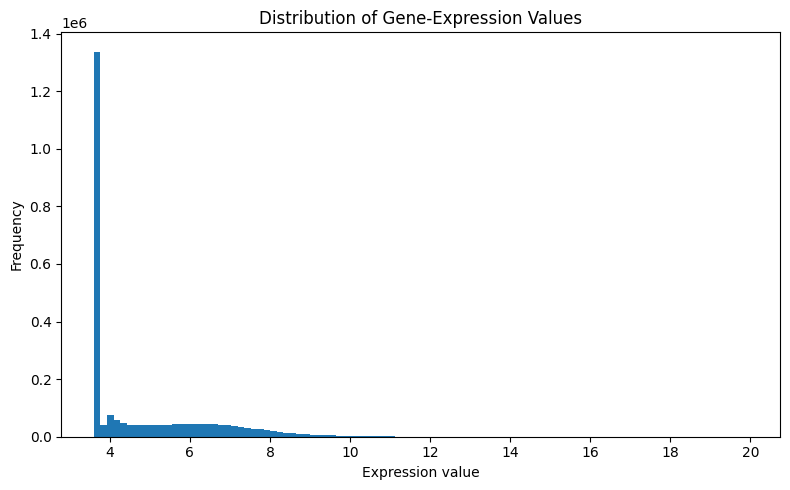

In [ ]:
import matplotlib.pyplot as plt

expression_values = expression.to_numpy().flatten()

plt.figure(figsize=(8, 5))
plt.hist(expression_values, bins=100)
plt.xlabel("Expression value")
plt.ylabel("Frequency")
plt.title("Distribution of Gene-Expression Values")
plt.tight_layout()
plt.show()

In [ ]:
sample_means = expression.mean(axis=0)

print(sample_means.describe())

count    68.000000
mean      4.755882
std       0.118563
min       3.971134
25%       4.743913
50%       4.772269
75%       4.793131
max       5.039617
dtype: float64


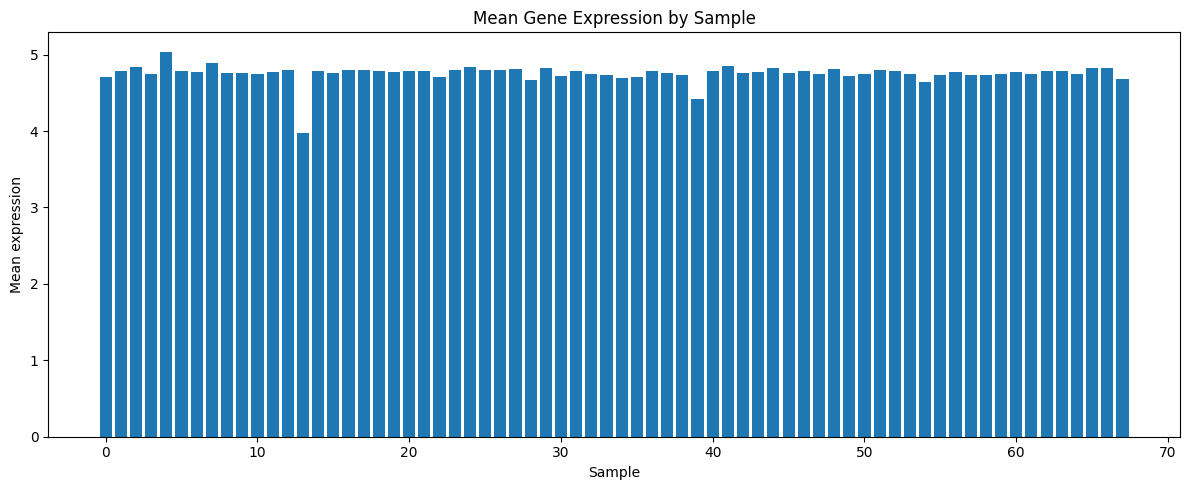

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.bar(range(len(sample_means)), sample_means.values)

plt.xlabel("Sample")
plt.ylabel("Mean expression")
plt.title("Mean Gene Expression by Sample")

plt.tight_layout()
plt.show()

In [ ]:
gene_variance = expression.var(axis=1)

top_1000 = gene_variance.sort_values(ascending=False).head(1000)

print("Total genes:", len(gene_variance))
print("Top variable genes:", len(top_1000))

print("\nTop 10 most variable genes:")
print(top_1000.head(10))

Total genes: 37361
Top variable genes: 1000

Top 10 most variable genes:
ENSG
ENSG00000227715    9.208329
ENSG00000227739    8.885844
ENSG00000235657    8.361034
ENSG00000183311    8.358560
ENSG00000229215    8.310461
ENSG00000206503    8.305527
ENSG00000196230    8.126750
ENSG00000206505    7.438107
ENSG00000146648    7.434869
ENSG00000012223    7.350056
dtype: float64


PC1 variance explained: 18.55 %
PC2 variance explained: 12.18 %


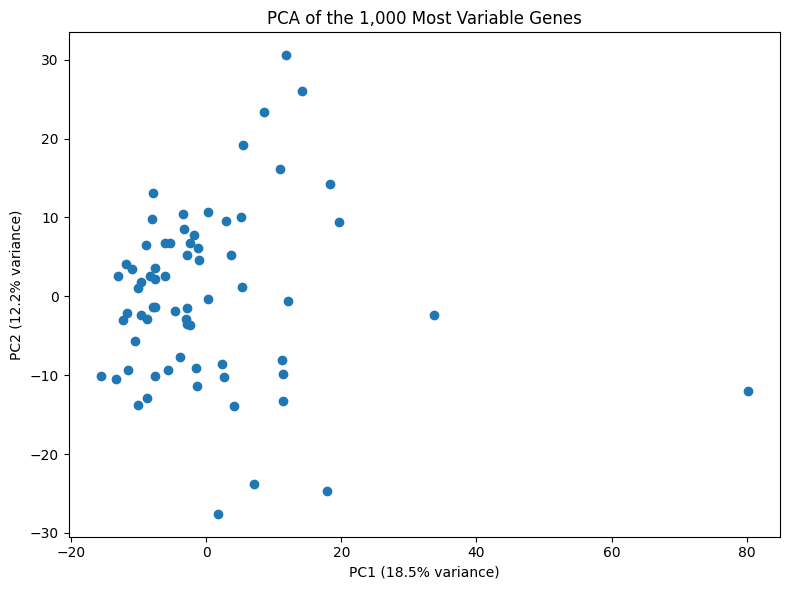

In [ ]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# Use the 1,000 most variable genes
pca_data = expression.loc[top_1000.index].T

# Standardize genes
scaler = StandardScaler()
scaled_data = scaler.fit_transform(pca_data)

# Run PCA
pca = PCA(n_components=2)
principal_components = pca.fit_transform(scaled_data)

# Create results table
pca_results = pd.DataFrame({
    "sample": pca_data.index,
    "PC1": principal_components[:, 0],
    "PC2": principal_components[:, 1]
})

print("PC1 variance explained:",
      round(pca.explained_variance_ratio_[0] * 100, 2), "%")

print("PC2 variance explained:",
      round(pca.explained_variance_ratio_[1] * 100, 2), "%")

# Plot
plt.figure(figsize=(8, 6))
plt.scatter(
    pca_results["PC1"],
    pca_results["PC2"]
)

plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)")
plt.title("PCA of the 1,000 Most Variable Genes")
plt.tight_layout()
plt.show()

In [ ]:
print("PC1 variance explained:",
      round(pca.explained_variance_ratio_[0] * 100, 2), "%")

print("PC2 variance explained:",
      round(pca.explained_variance_ratio_[1] * 100, 2), "%")

PC1 variance explained: 18.55 %
PC2 variance explained: 12.18 %


In [ ]:
RESULTS_DIR = "/content/drive/MyDrive/GSE149009/results"

import os
os.makedirs(RESULTS_DIR, exist_ok=True)

pca_results.to_csv(
    f"{RESULTS_DIR}/pca_coordinates.csv",
    index=False
)

print("PCA results saved.")

PCA results saved.


In [ ]:
survival_data = clinical.dropna(subset=["survival_days"]).copy()

print("Total samples:", len(clinical))
print("Samples with survival data:", len(survival_data))
print("Samples missing survival data:", clinical["survival_days"].isna().sum())

print("\nSurvival summary:")
print(survival_data["survival_days"].describe())

Total samples: 68
Samples with survival data: 59
Samples missing survival data: 9

Survival summary:
count      59.000000
mean      875.491525
std      1071.064848
min        22.000000
25%       105.500000
50%       171.000000
75%      1390.500000
max      3896.000000
Name: survival_days, dtype: float64


In [ ]:
qc_summary = pd.DataFrame({
    "number_of_genes": [expression.shape[0]],
    "number_of_samples": [expression.shape[1]],
    "total_missing_values": [int(expression.isna().sum().sum())],
    "total_zero_values": [int((expression == 0).sum().sum())]
})

qc_summary.to_csv(
    "/content/drive/MyDrive/GSE149009/results/expression_qc_summary.csv",
    index=False
)

print("QC summary saved.")

QC summary saved.
